# Experiment 2: Stability, correctness and class-specific responses
## Same 40 test images per class, seed 42, three noise realizations; run-1 ResNet18 224, ResNet50 28 and original ViT

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

seed, per_class, batch_size = 42, 40, 32
torch.manual_seed(seed)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
output = Path('predictions/stability.npz')
output.parent.mkdir(exist_ok=True)
print(device)
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))

cuda


## Ten non-identity levels per operation — translation in subpixels, noise σ on [0, 1], blur radius in pixels

In [2]:
levels = {
    'rotation': np.linspace(-20, 20, 10),
    'translation': np.linspace(-3, 3, 10),
    'brightness': np.linspace(0.8, 1.2, 10),
    'blur': np.linspace(0.15, 1.5, 10),
    'noise': np.linspace(0.01, 0.1, 10),
    'green_scale': np.linspace(0.9, 1.1, 10),
    'red_scale': np.linspace(0.9, 1.1, 10),
    'blue_scale': np.linspace(0.9, 1.1, 10),
}
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    test_images = data['test_images']
    test_labels = data['test_labels'].ravel()
rng = np.random.default_rng(seed)
indices = np.sort(np.concatenate([rng.choice(np.flatnonzero(test_labels == c), per_class, replace=False)
                                 for c in range(8)]))
images, labels = test_images[indices], test_labels[indices]
baseline = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)[indices]
    np.testing.assert_array_equal(rows[:, 0], indices)
    np.testing.assert_array_equal(rows[:, 1], labels)
    baseline.append(rows[:, 3:])
baseline = np.stack(baseline)
base_class = baseline.argmax(-1)
all_correct = (base_class == labels).all(axis=0)
print(f'{len(images)} images; {all_correct.sum()} initially correct for all models')

320 images; 297 initially correct for all models


## Transform original 28 × 28 RGB images — shared inputs for both models, gray borders, no wraparound

In [3]:
def transform(images, kind, level, repeat=0):
    result = []
    for i, image in enumerate(images):
        pil = Image.fromarray(image)
        if kind == 'rotation':
            changed = pil.rotate(float(level), resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'translation':
            changed = pil.transform(pil.size, Image.Transform.AFFINE, (1, 0, -float(level), 0, 1, 0),
                                    resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'brightness':
            changed = ImageEnhance.Brightness(pil).enhance(float(level))
        elif kind == 'blur':
            changed = pil.filter(ImageFilter.GaussianBlur(float(level)))
        elif kind == 'noise':
            key = f'{seed}:{i}:{level}:{repeat}'
            noise_seed = int.from_bytes(hashlib.sha256(key.encode()).digest()[:8], 'little')
            noise = np.random.default_rng(noise_seed).normal(0, level, image.shape)
            changed = np.rint(np.clip(image / 255.0 + noise, 0, 1) * 255).astype(np.uint8)
        else:
            channel = {'red_scale': 0, 'green_scale': 1, 'blue_scale': 2}[kind]
            changed = image.astype(float)
            changed[..., channel] *= level
            changed = np.rint(np.clip(changed, 0, 255)).astype(np.uint8)
        result.append(np.asarray(changed))
    return np.stack(result)

## Load models and predict in batches

In [4]:
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

baseline_logits = []
for m in range(len(models)):
    p, scores = predict(m, images)
    np.testing.assert_allclose(p, baseline[m], atol=1e-5, rtol=1e-4)
    baseline_logits.append(scores)


## Run experiment and save full probabilities and raw logits — model × level × realization × image × class

In [5]:
probabilities, logits = {}, {}
for kind, values in levels.items():
    repeats = 3 if kind == 'noise' else 1
    p = np.empty((len(models), len(values), repeats, len(images), 8), dtype=np.float32)
    scores = np.empty_like(p)
    for j, level in enumerate(values):
        for repeat in range(repeats):
            changed = transform(images, kind, level, repeat)
            for m in range(len(models)):
                p[m, j, repeat], scores[m, j, repeat] = predict(m, changed)
    probabilities[kind], logits[kind] = p, scores
    print(f'{kind}: {len(values)} levels completed')
np.savez_compressed(output, **probabilities, baseline=baseline, indices=indices, labels=labels,
                    seed=seed, model_names=model_names, class_names=class_names,
                    checkpoints=checkpoints, model_input_resolutions=[224, 28, 224],
                    baseline_logits=np.stack(baseline_logits), split='test',
                    axes=['model', 'level', 'realization', 'image', 'class'],
                    border_fill_rgb=[128, 128, 128], input_shape=[28, 28, 3],
                    **{f'logits_{kind}': scores for kind, scores in logits.items()},
                    **{f'levels_{kind}': values for kind, values in levels.items()})
print(output)

rotation: 10 levels completed


translation: 10 levels completed


brightness: 10 levels completed


blur: 10 levels completed


noise: 10 levels completed


green_scale: 10 levels completed


red_scale: 10 levels completed


blue_scale: 10 levels completed
predictions\stability.npz


## Load saved results — average noise realizations within each image, not as independent images

In [6]:
with np.load(output, allow_pickle=False) as saved:
    levels = {kind: saved[f'levels_{kind}'] for kind in levels}
    probabilities = {kind: saved[kind] for kind in levels}
    baseline, indices, labels = saved['baseline'], saved['indices'], saved['labels']
    model_names = saved['model_names'].tolist()
    seed = int(saved['seed'])
images = test_images[indices]
base_class = baseline.argmax(-1)
base_probability = np.take_along_axis(baseline, base_class[..., None], axis=-1)[..., 0]
all_correct = (base_class == labels).all(axis=0)
metrics = {}
for kind, p in probabilities.items():
    predicted = p.argmax(-1)
    target = np.broadcast_to(base_class[:, None, None, :, None], p.shape[:-1] + (1,))
    retained = np.take_along_axis(p, target, axis=-1)[..., 0].mean(axis=2)
    correct = (predicted == labels).mean(axis=2)
    metrics[kind] = {
        'Change in p(original class)': retained - base_probability[:, None, :],
        'Label flip fraction': (predicted != base_class[:, None, None, :]).mean(axis=2),
        'Accuracy (all images)': correct,
        'Correct-label retention (all initially correct)': correct[:, :, all_correct],
        'Correct → wrong': (1 - correct) * (base_class == labels)[:, None, :],
        'Wrong → correct': correct * (base_class != labels)[:, None, :],
    }

## 2A — Stability and correctness: ten points per operation; dashed lines mark unmodified references

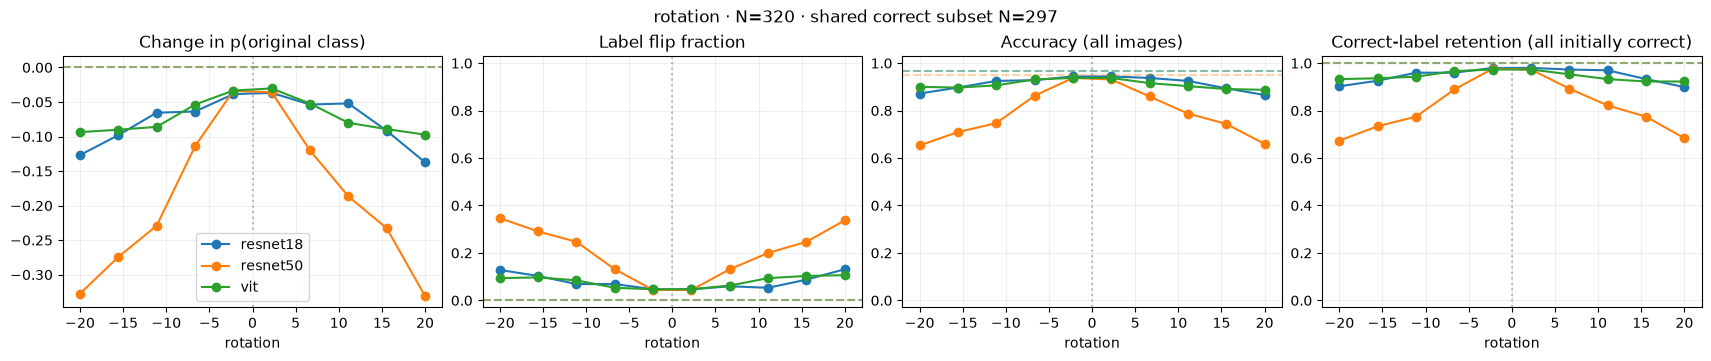

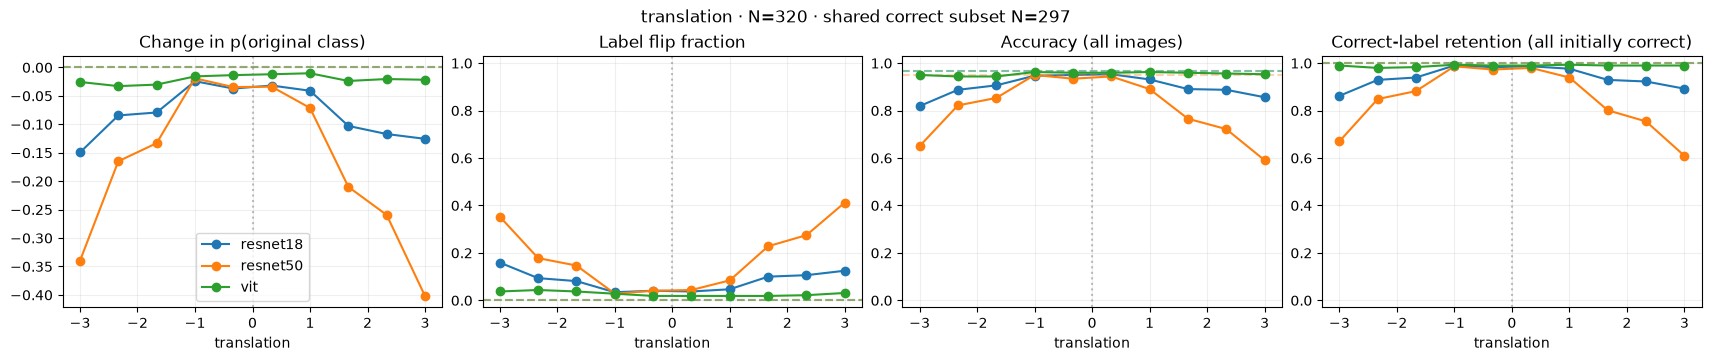

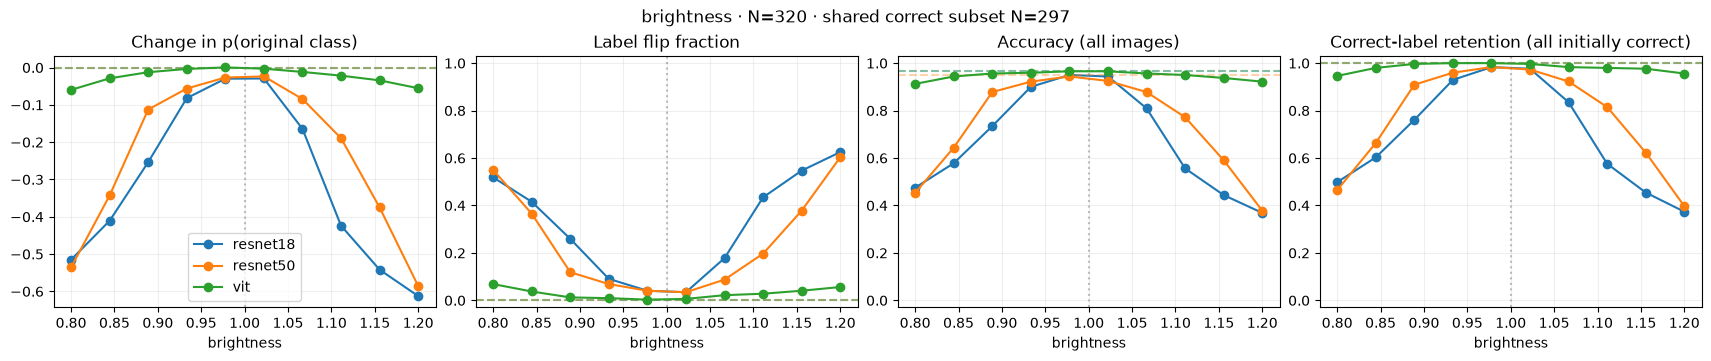

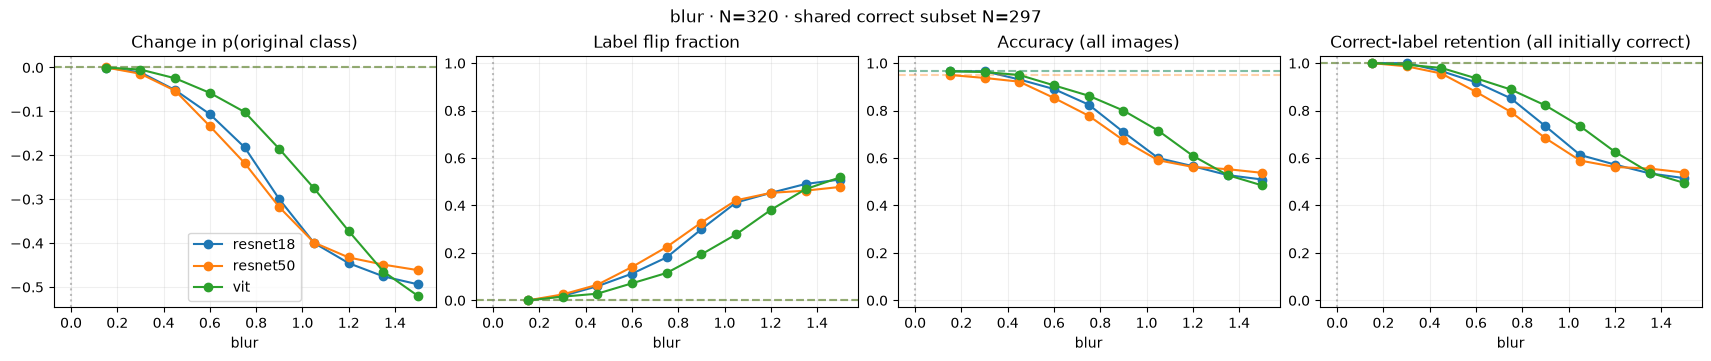

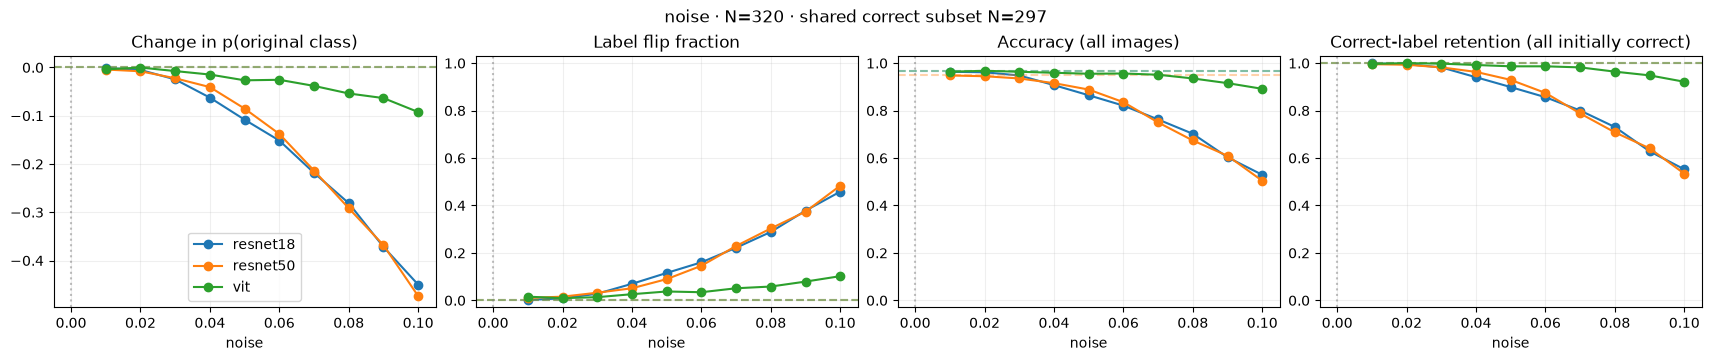

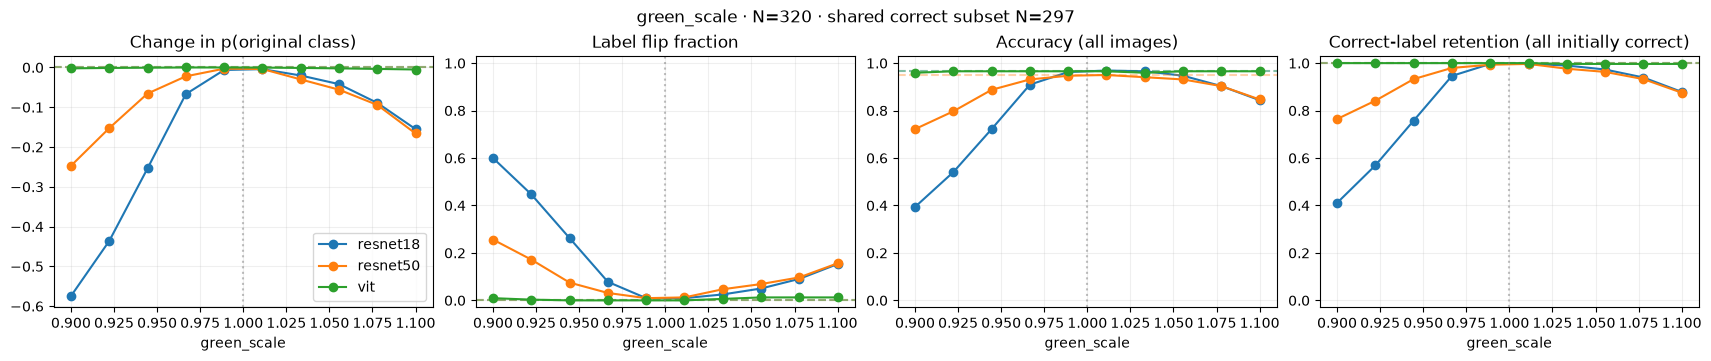

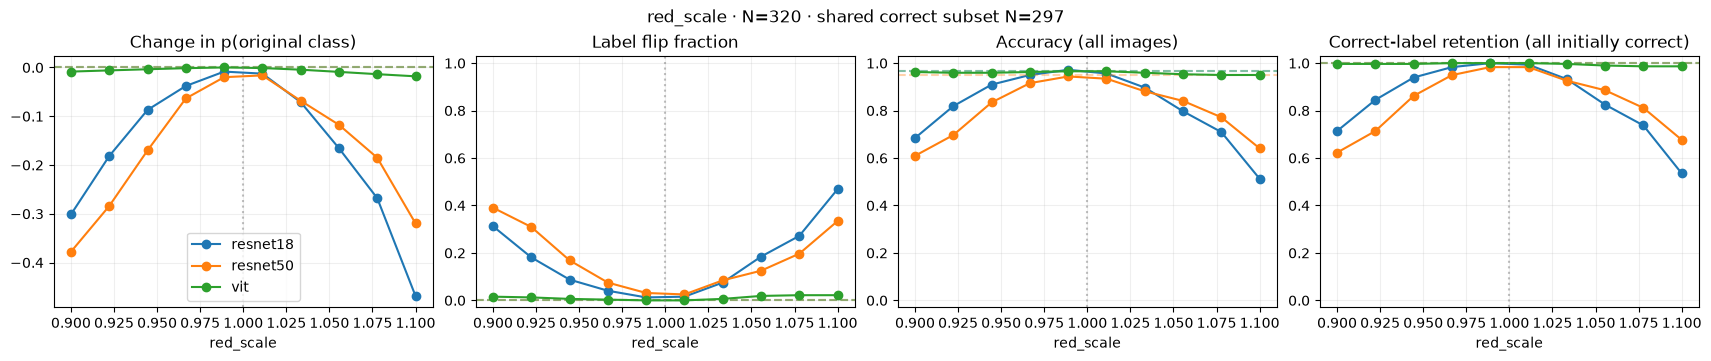

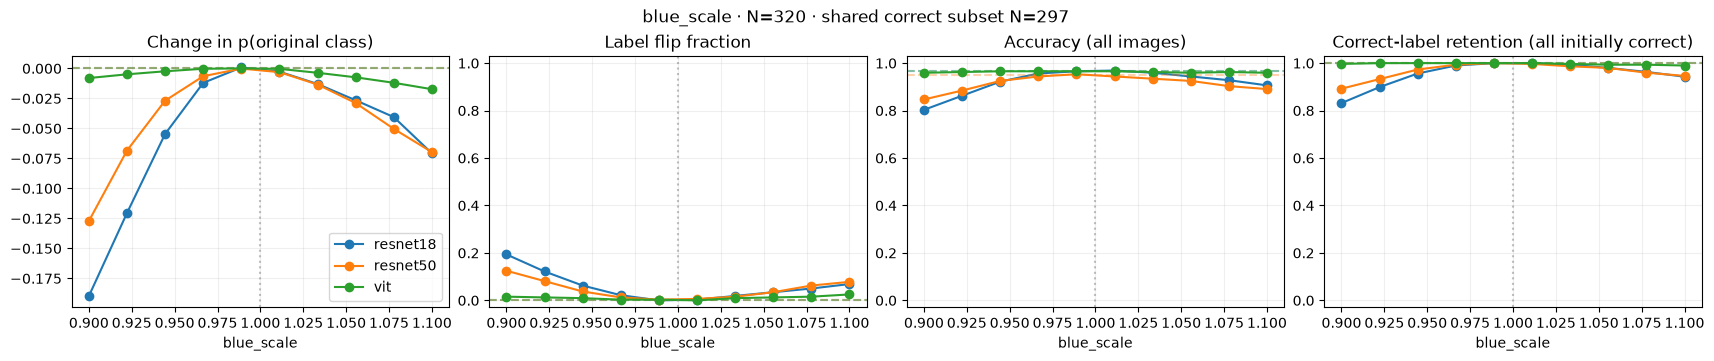

In [7]:
for kind, values in levels.items():
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.5), layout='constrained')
    reference = 1 if kind in ('brightness', 'green_scale', 'red_scale', 'blue_scale') else 0
    for ax, title in zip(axes, list(metrics[kind])[:4]):
        for m, name in enumerate(model_names):
            data = metrics[kind][title][m]
            y = data.mean(axis=-1) if data.shape[-1] else np.full(10, np.nan)
            line, = ax.plot(values, y, 'o-', label=name)
            base = (base_class[m] == labels).mean() if title.startswith('Accuracy') else (1 if title.startswith('Correct-label') else 0)
            ax.axhline(base, color=line.get_color(), ls='--', alpha=0.35)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        if not title.startswith('Change'):
            ax.set_ylim(-0.03, 1.03)
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(labels)} · shared correct subset N={all_correct.sum()}')
    plt.show()

## Correctness transitions — fractions of all images, averaged over noise realizations

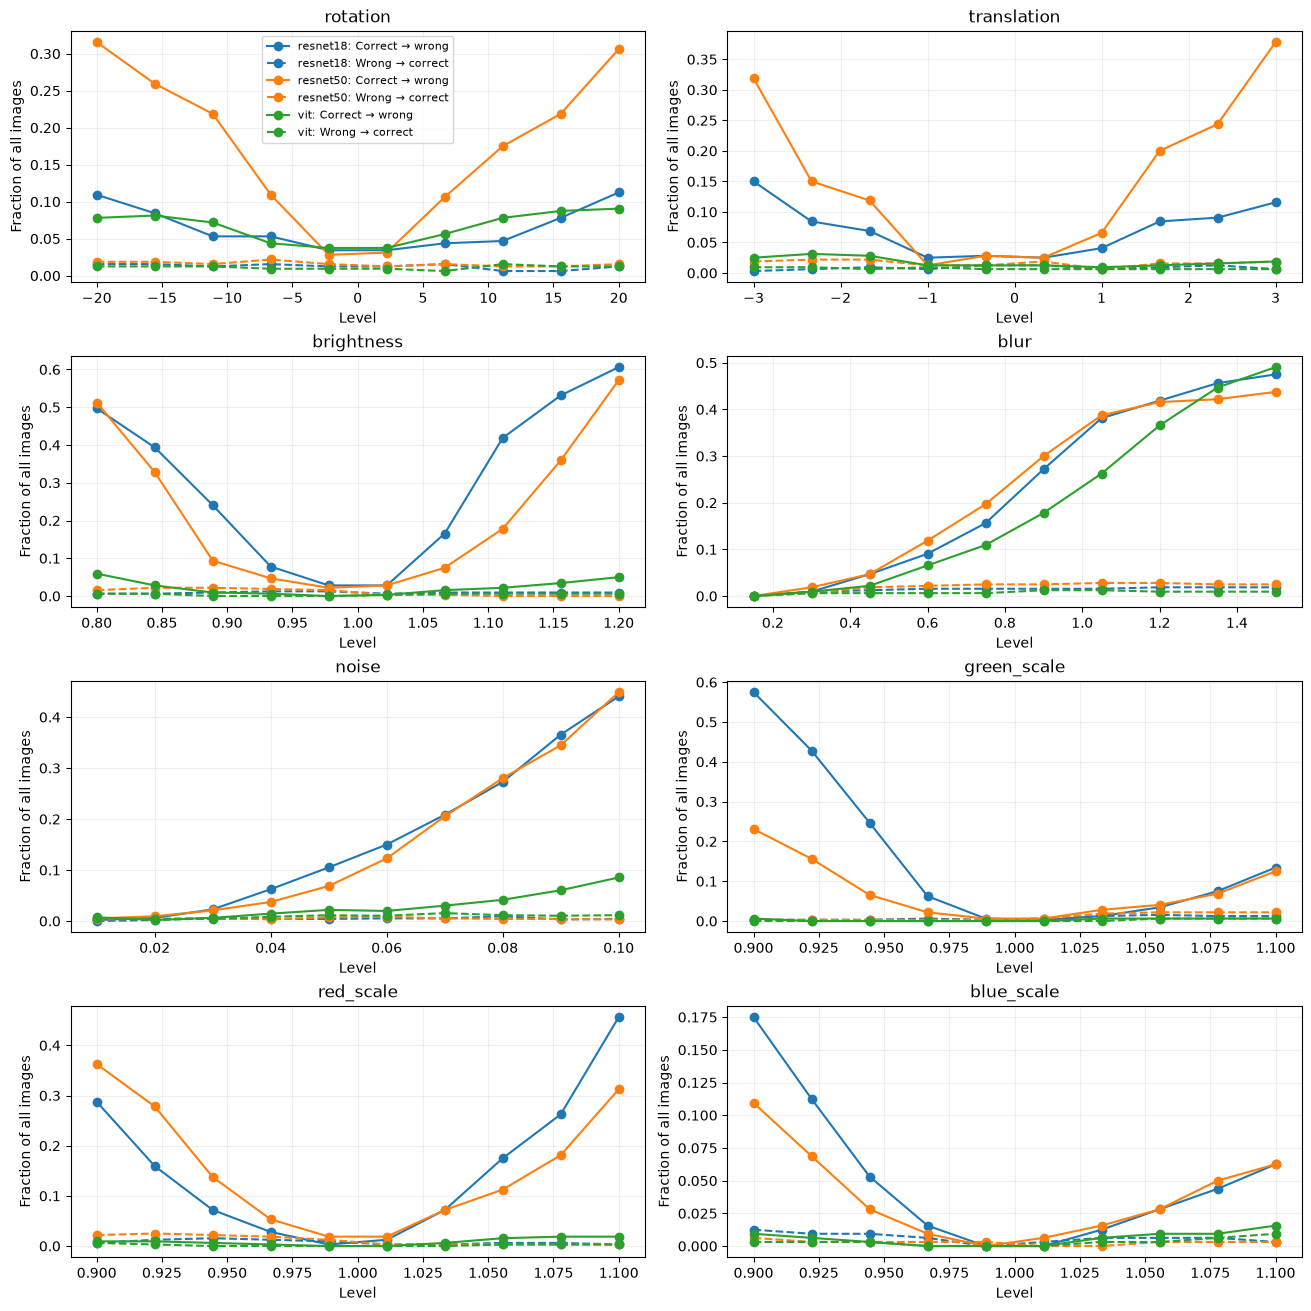

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout='constrained')
for ax, (kind, values) in zip(axes.flat, levels.items()):
    for m, name in enumerate(model_names):
        for title, style in [('Correct → wrong', '-'), ('Wrong → correct', '--')]:
            ax.plot(values, metrics[kind][title][m].mean(-1), style,
                    color=f'C{m}', marker='o', label=f'{name}: {title}')
    ax.set(title=kind, xlabel='Level', ylabel='Fraction of all images')
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.show()

## 2B — Class-specific responses: equal weight per level, grouped by true class; stability is not accuracy

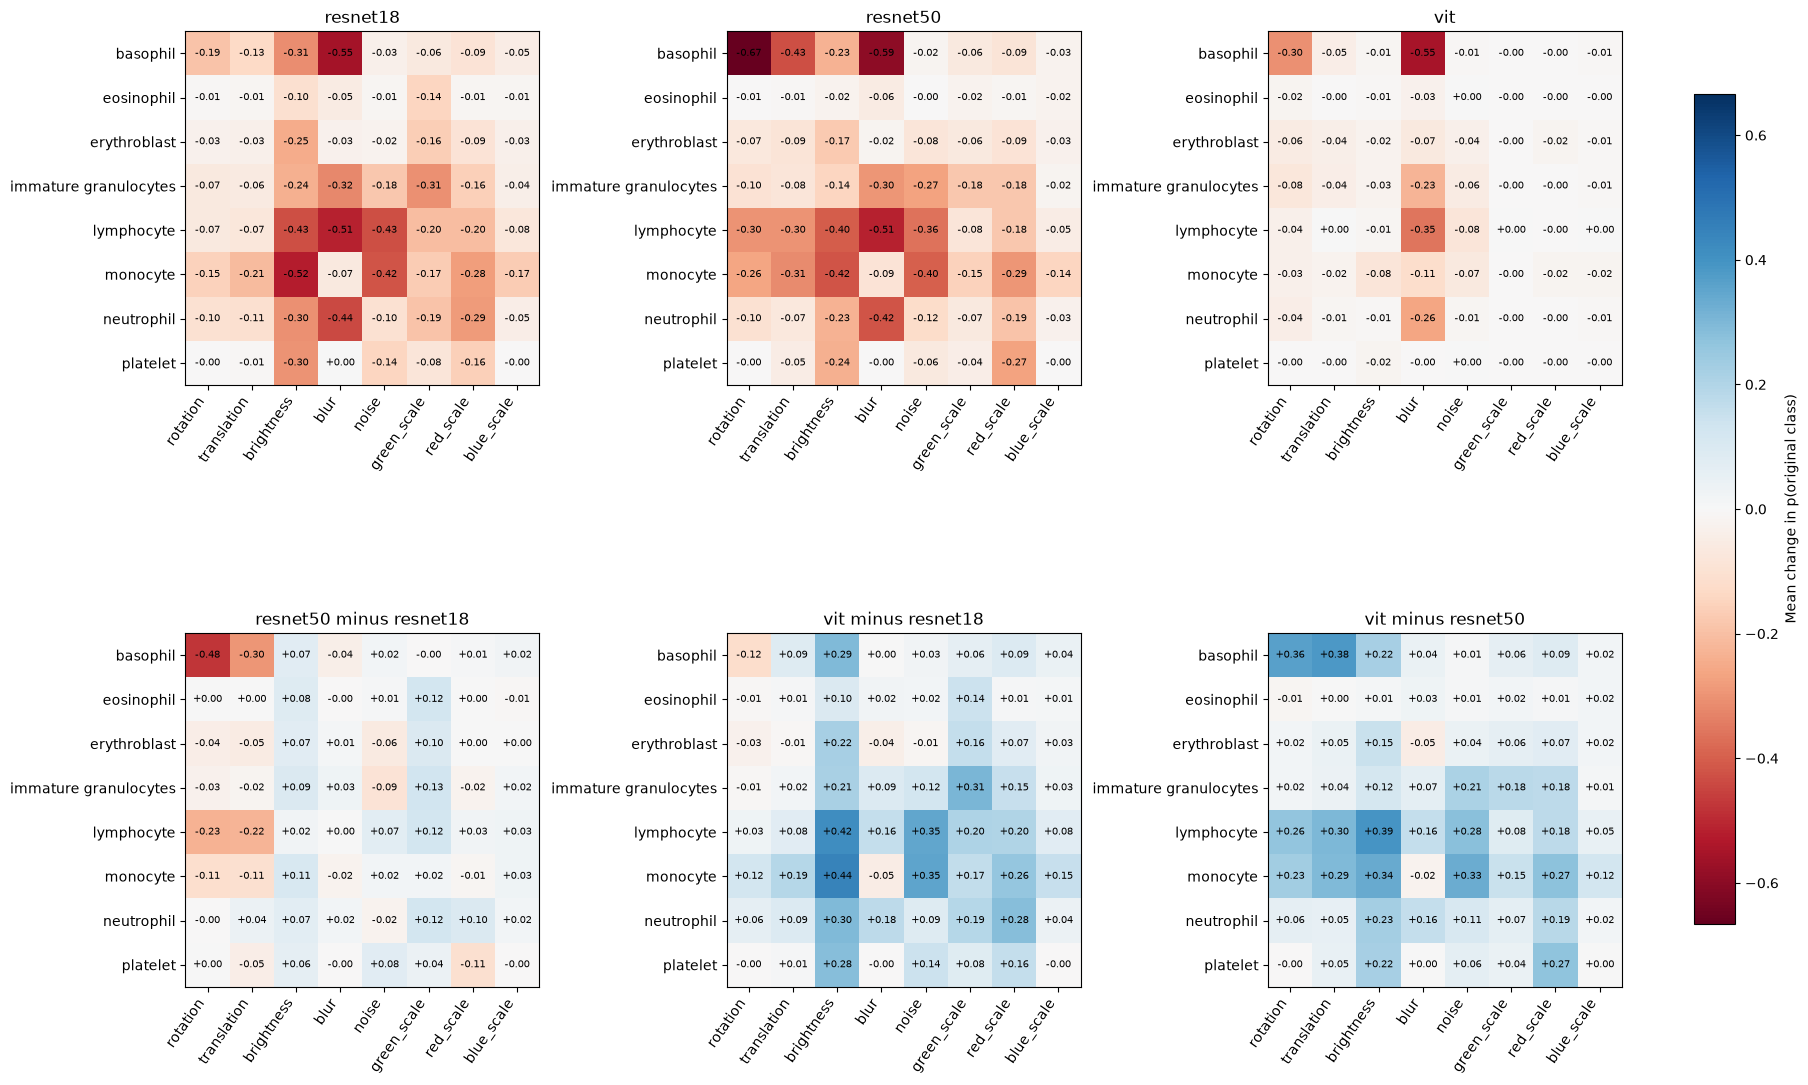

In [9]:
fingerprints = np.stack([np.array([
    metrics[kind]['Change in p(original class)'][m][:, labels == c].mean()
    for c in range(8) for kind in levels]).reshape(8, 8) for m in range(len(model_names))])
matrices = [*fingerprints, *[fingerprints[j] - fingerprints[i] for i, j in pairs]]
titles = [*model_names, *[f'{model_names[j]} minus {model_names[i]}' for i, j in pairs]]
scale = max(np.abs(matrices).max(), 0.01)
fig, axes = plt.subplots(2, 3, figsize=(18, 12), layout='constrained')
for ax, matrix, title in zip(axes.flat, matrices, titles):
    im = ax.imshow(matrix, cmap='RdBu', vmin=-scale, vmax=scale)
    ax.set(title=title, xticks=range(8), xticklabels=list(levels), yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=55, ha='right')
    for c in range(8):
        for j in range(8):
            ax.text(j, c, f'{matrix[c, j]:+.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.7, label='Mean change in p(original class)')
plt.show()


## 2C — Two largest probability-drop examples per operation: selected, not representative; noise realization 0; class IDs follow data/metadata.json

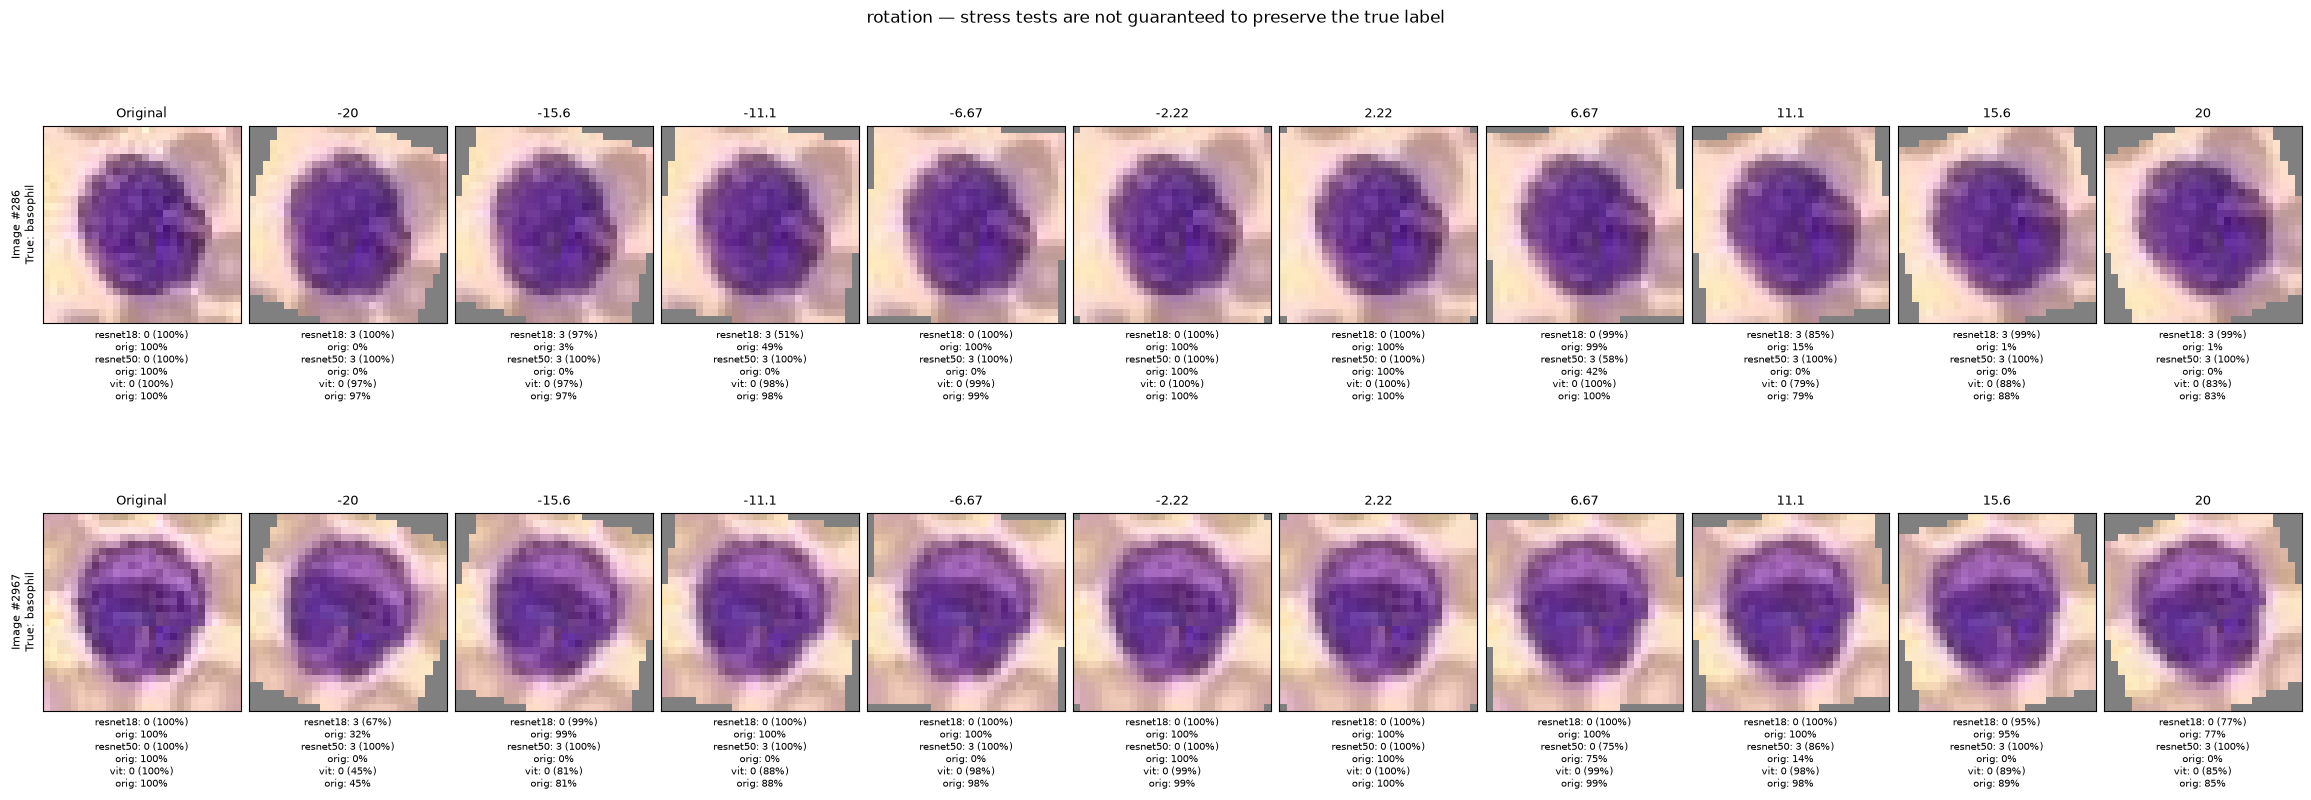

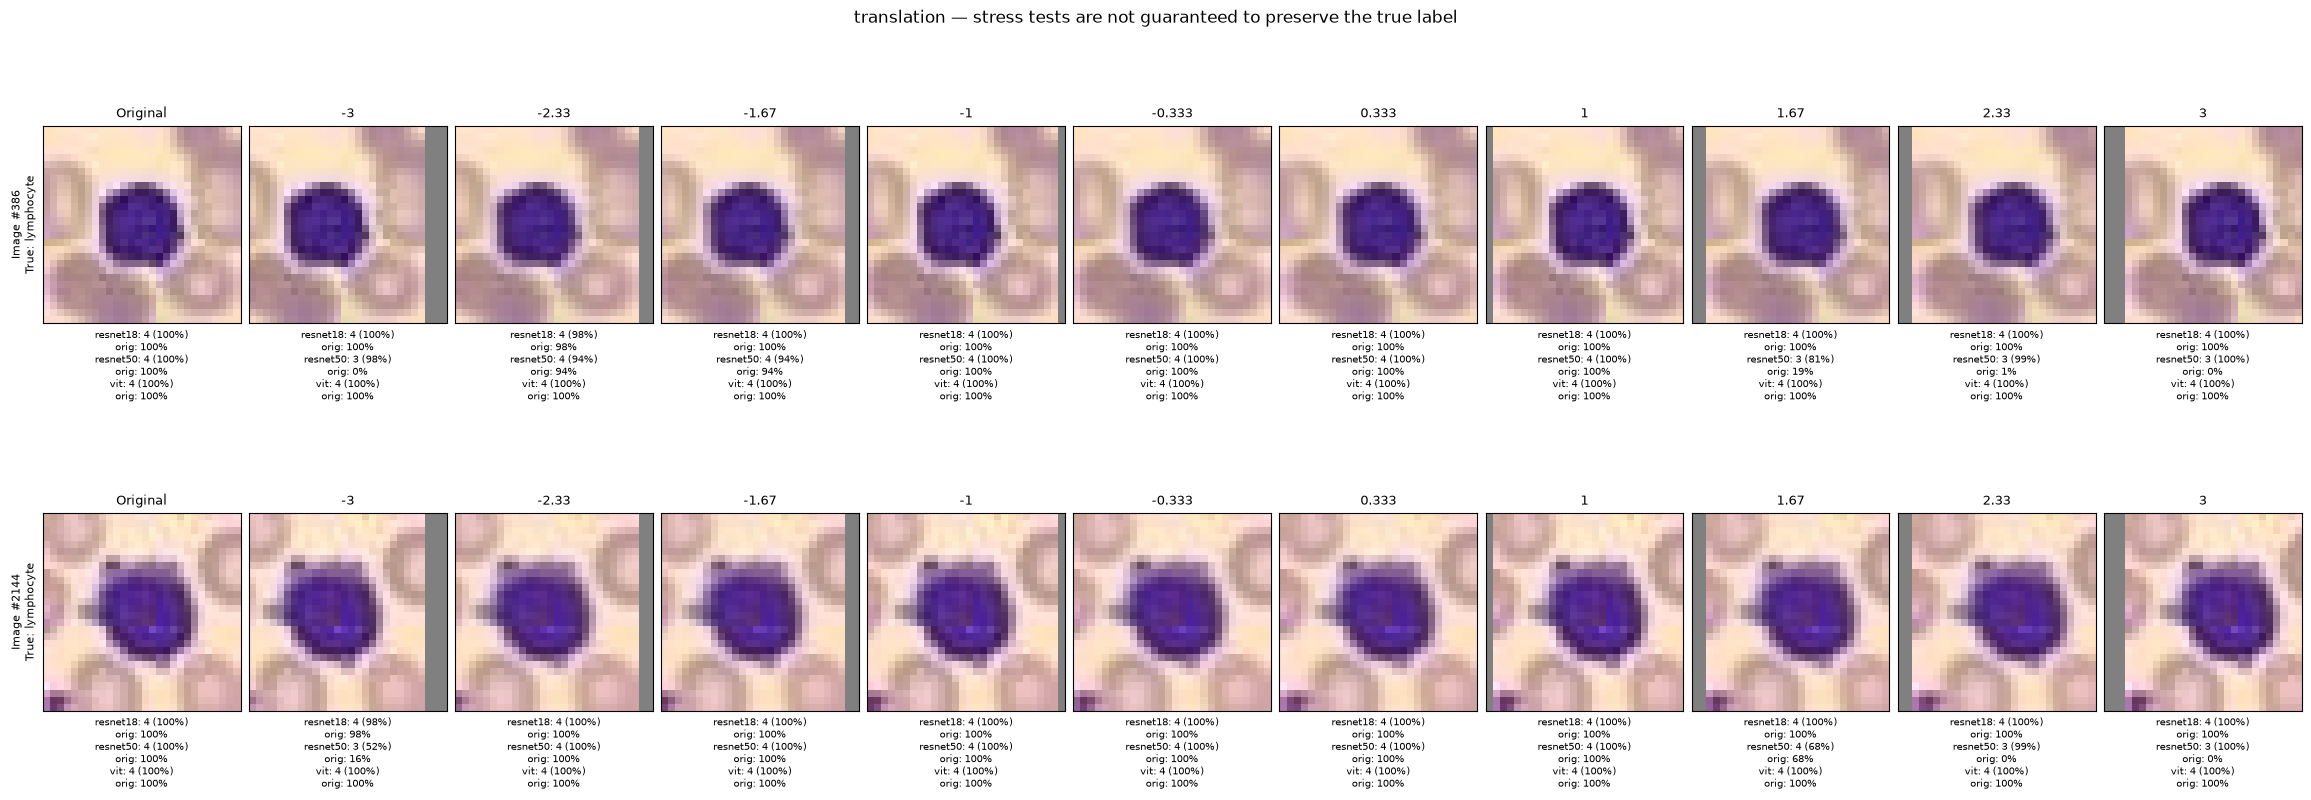

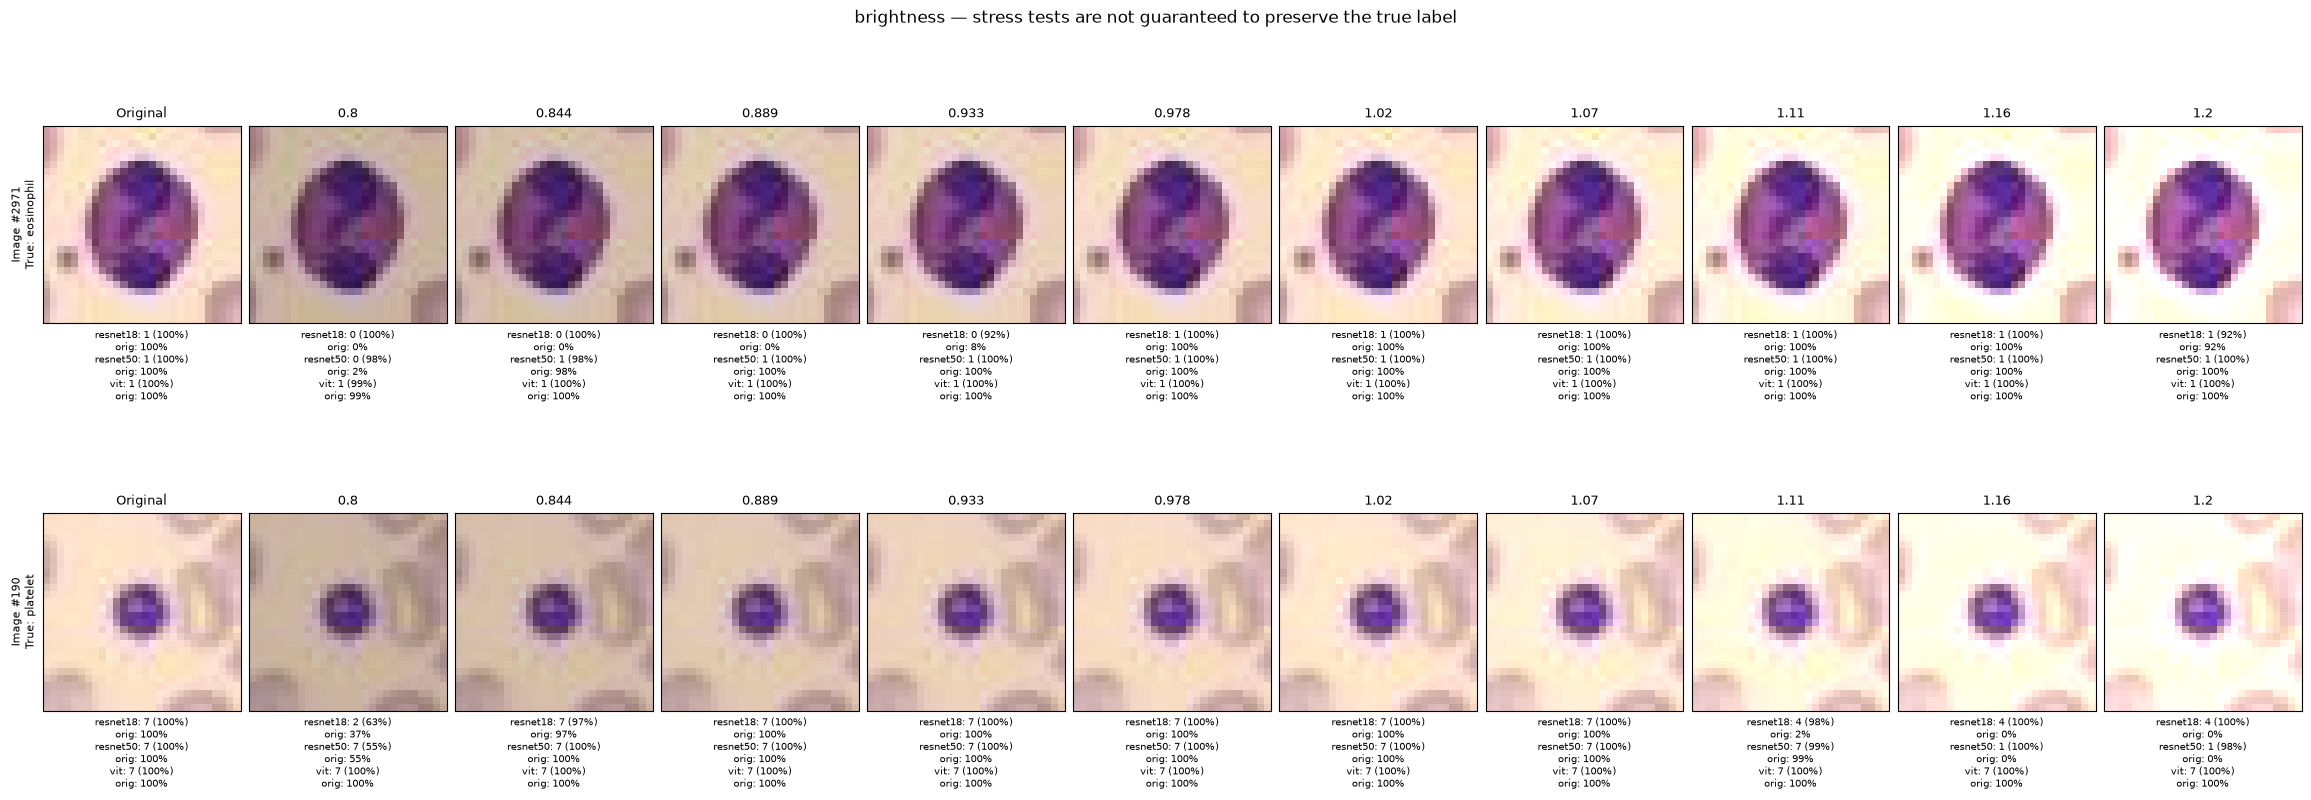

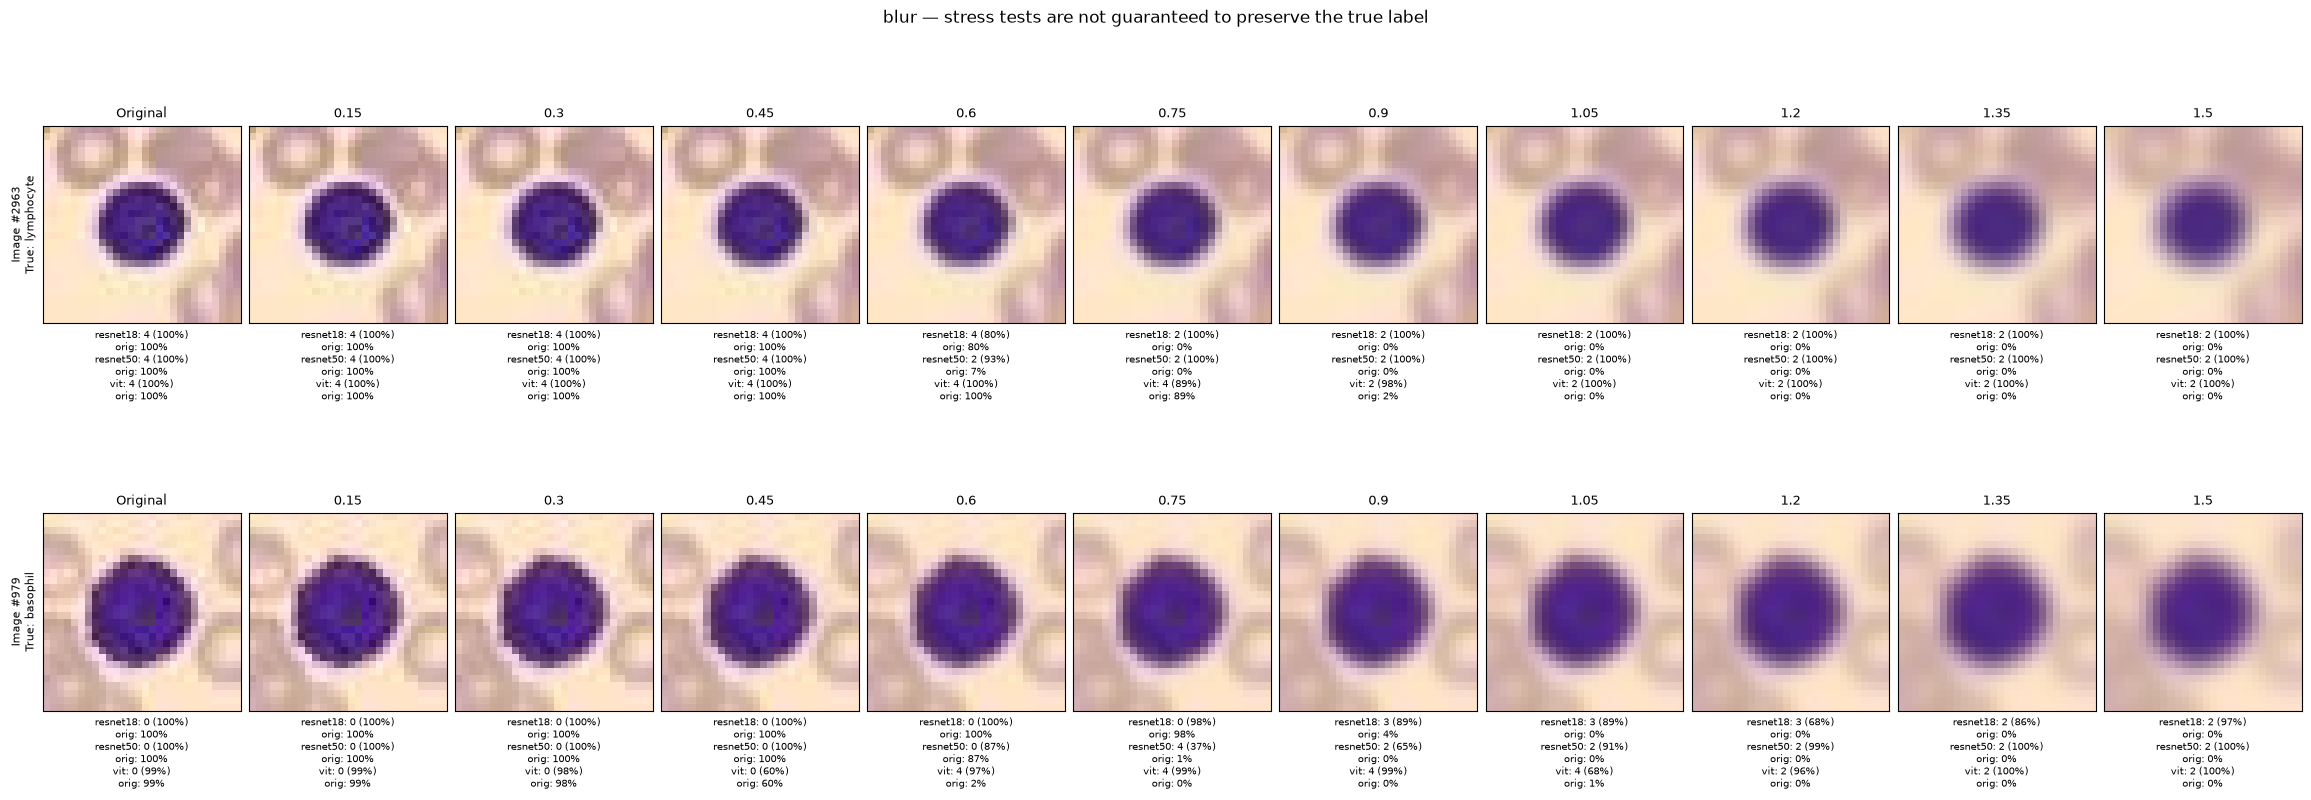

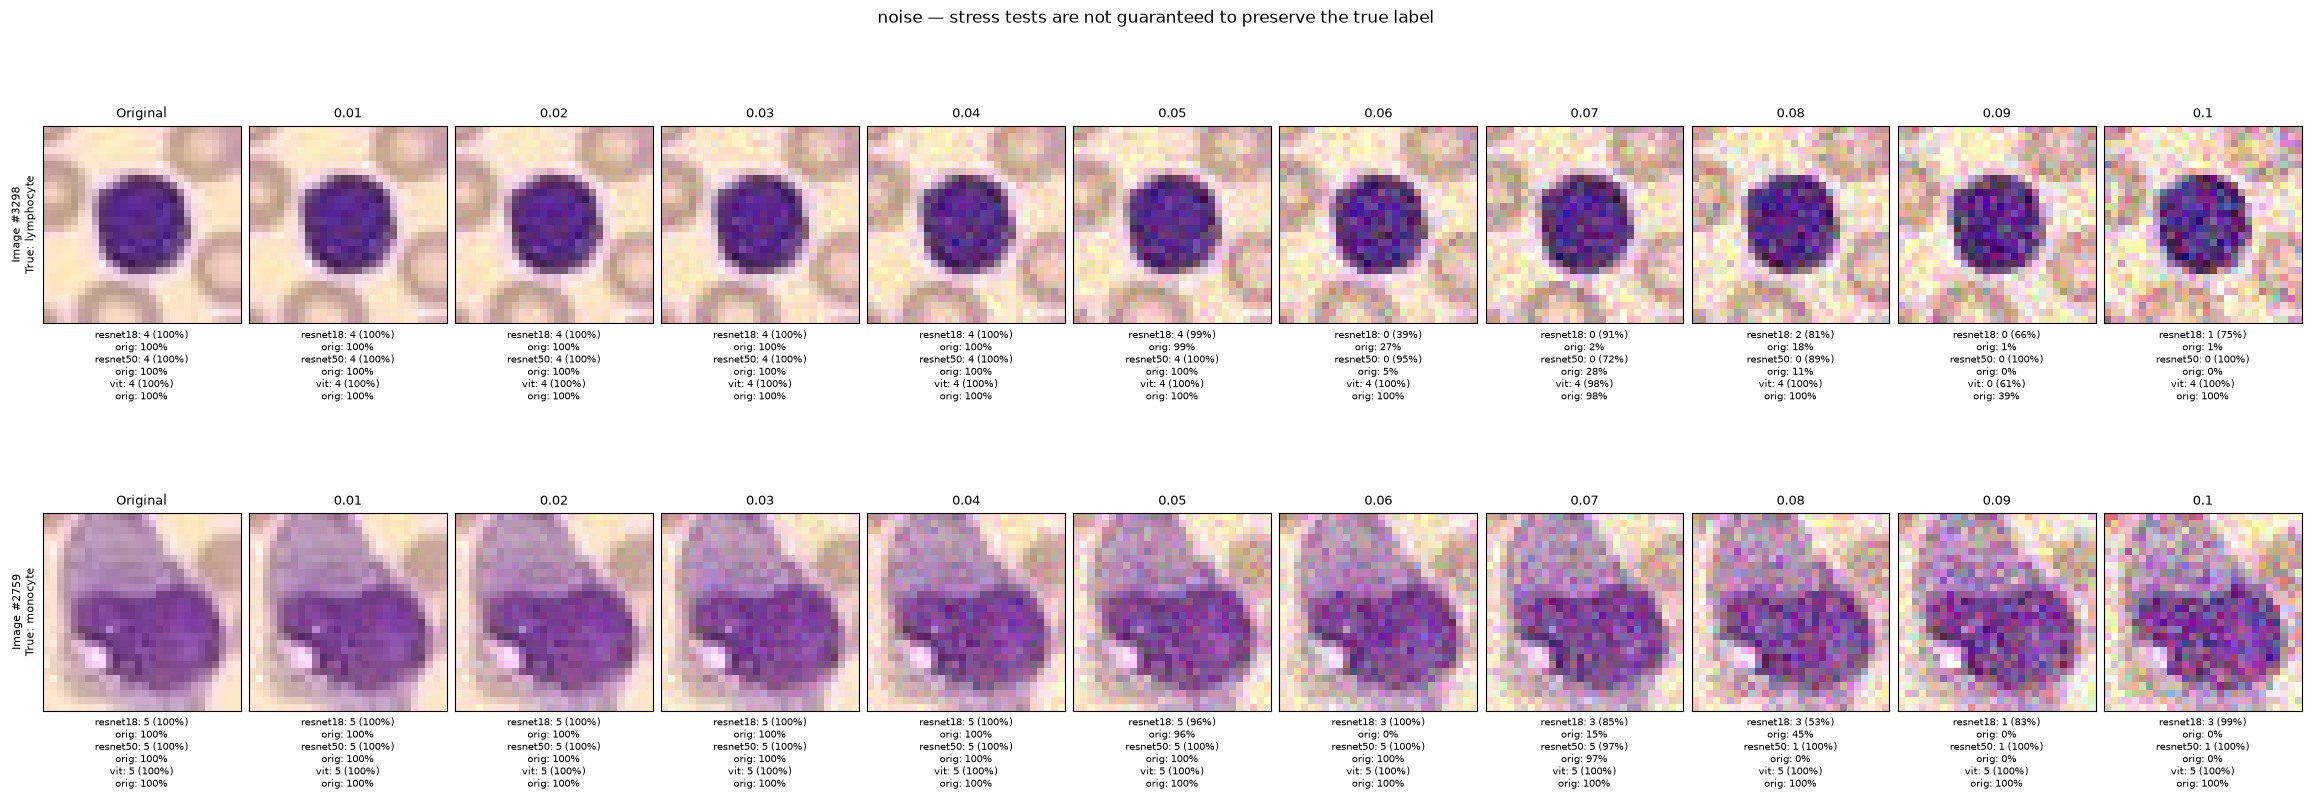

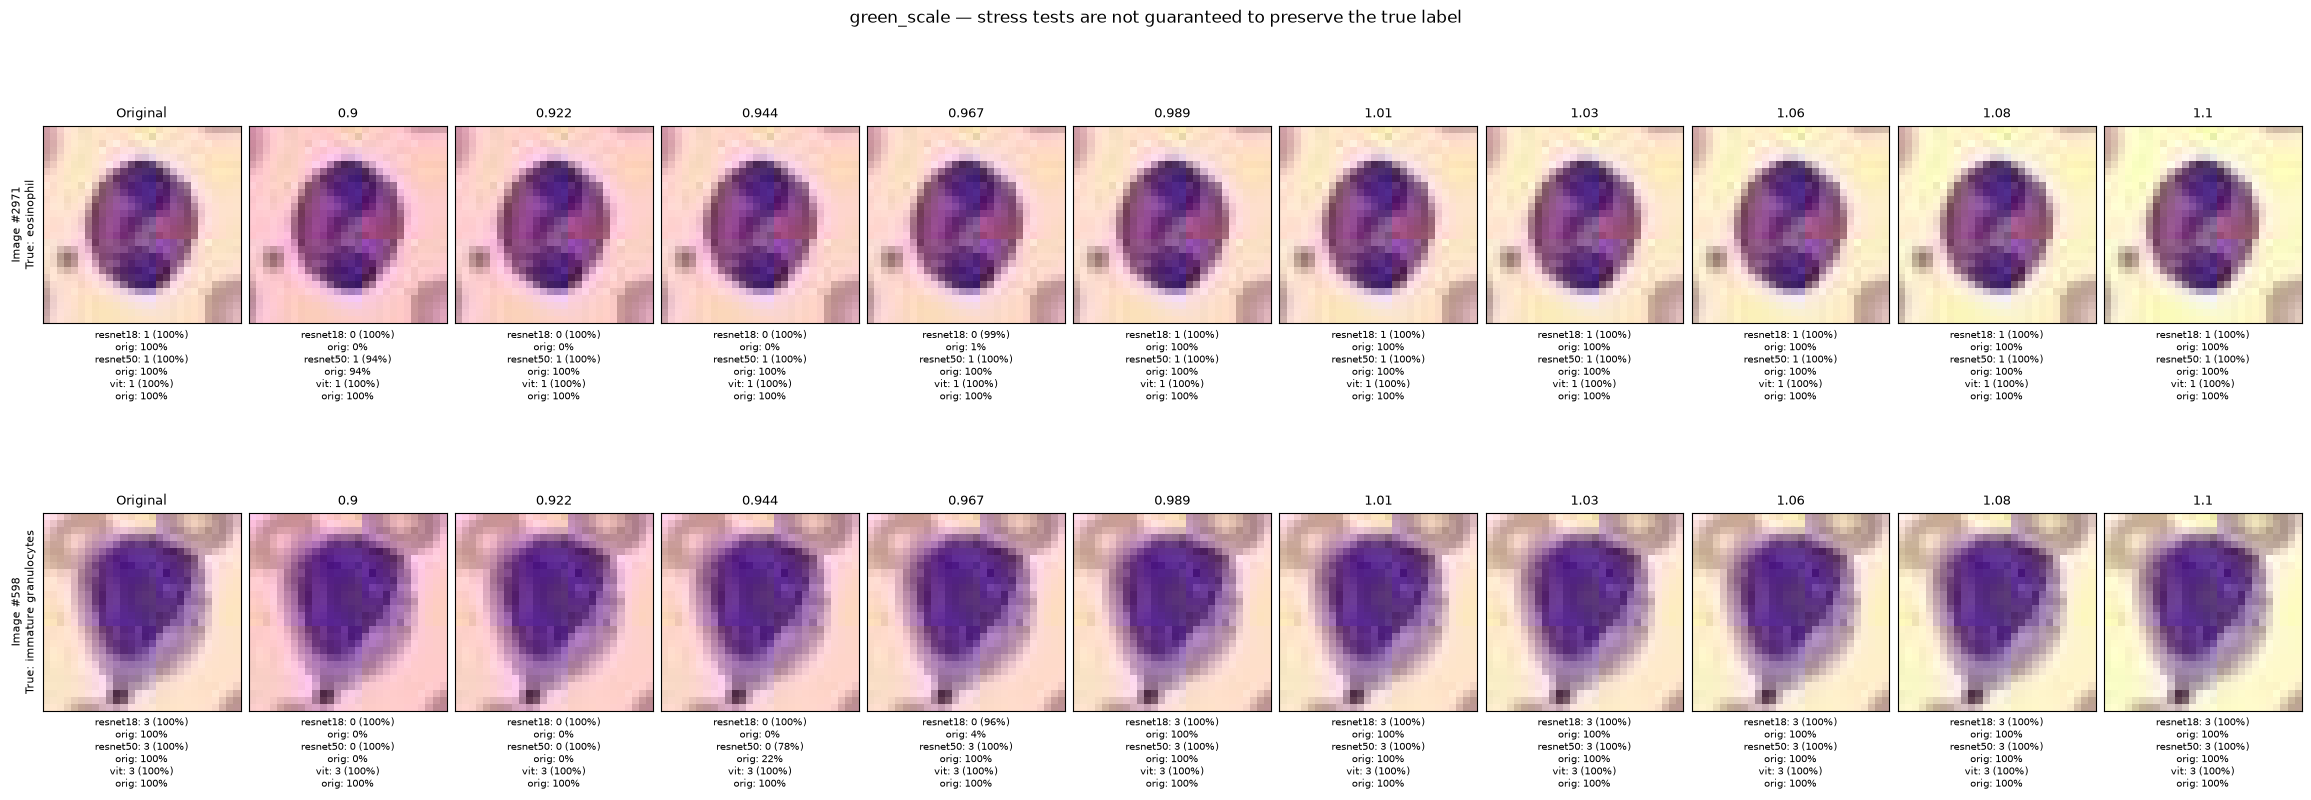

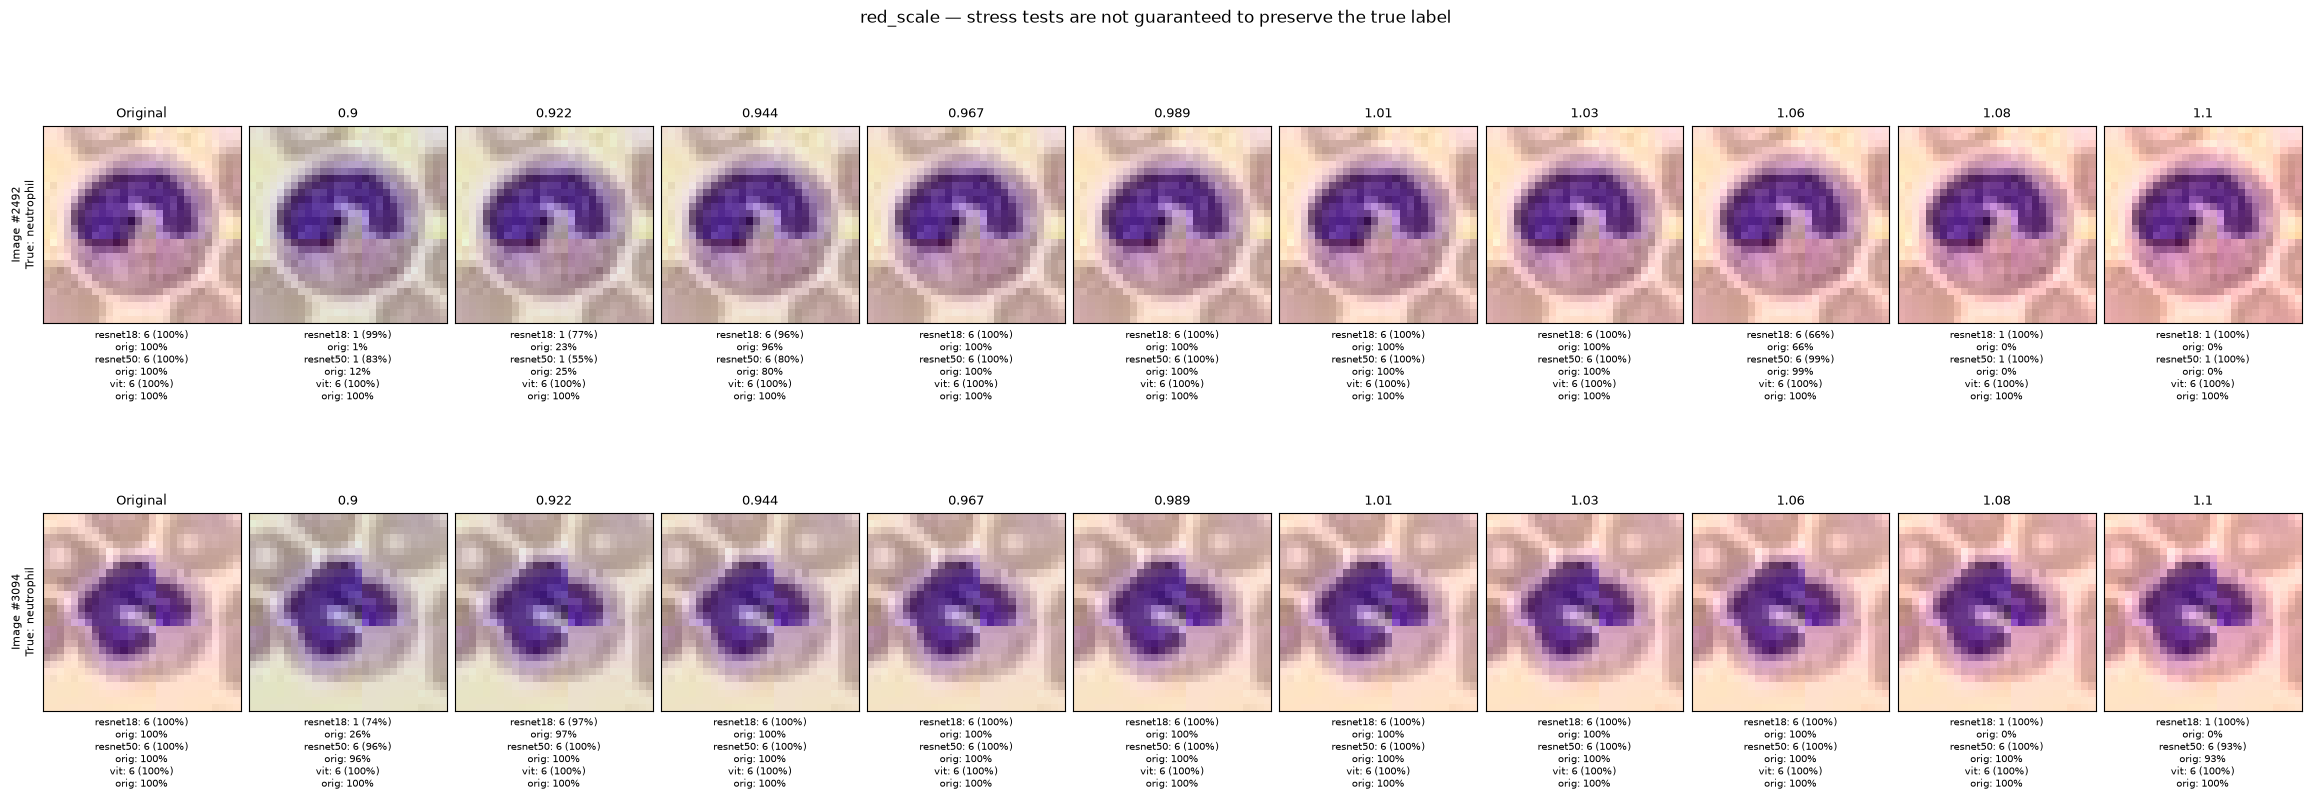

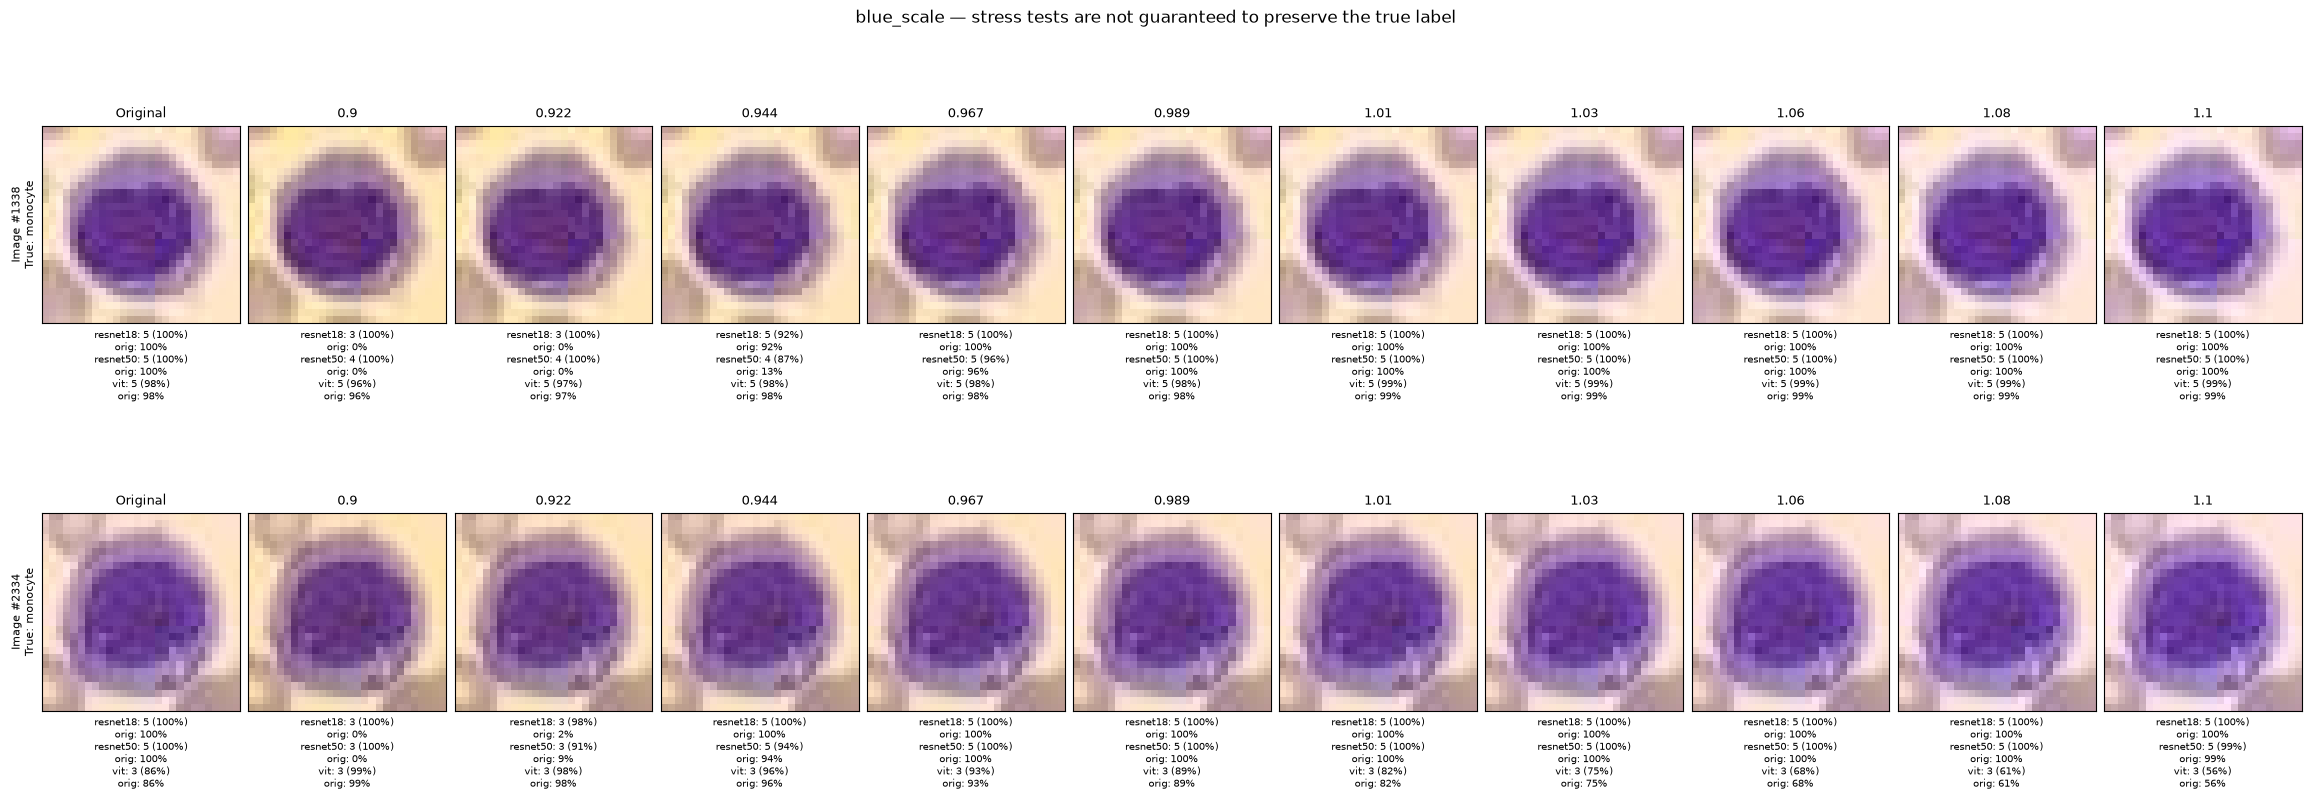

In [10]:
for kind, values in levels.items():
    p0 = np.take_along_axis(probabilities[kind][:, :, 0], base_class[:, None, :, None], axis=-1)[..., 0]
    drop = (base_probability[:, None, :] - p0).max(axis=(0, 1))
    positions = np.argsort(-drop, kind='stable')[:2]
    changed = [transform(images, kind, level, repeat=0)[positions] for level in values]
    fig, axes = plt.subplots(2, 11, figsize=(23, 8), layout='constrained')
    for row, pos in enumerate(positions):
        for col in range(11):
            ax = axes[row, col]
            ax.imshow(images[pos] if col == 0 else changed[col - 1][row])
            p = baseline[:, pos] if col == 0 else probabilities[kind][:, col - 1, 0, pos]
            details = []
            for m, name in enumerate(model_names):
                pred = p[m].argmax()
                details.append(f'{name}: {pred} ({p[m, pred]:.0%})\norig: {p[m, base_class[m, pos]]:.0%}')
            ax.set_title('Original' if col == 0 else f'{values[col - 1]:.3g}', fontsize=9)
            ax.set_xlabel('\n'.join(details), fontsize=7)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].set_ylabel(f'Image #{indices[pos]}\nTrue: {class_names[labels[pos]]}', fontsize=8)
    fig.suptitle(f'{kind} — stress tests are not guaranteed to preserve the true label')
    plt.show()